# 02 · Which night of the week is worst?

Gut feeling going in: Sunday. Let's see.

In [1]:
from sleep_patterns.clean import nightly
from sleep_patterns.io import load_sleep
from sleep_patterns.metrics import weekday_summary, worst_weekday
from sleep_patterns import plots

nights = nightly(load_sleep())
summary = weekday_summary(nights)
summary.round(2)

,nights,mean_hours,median_hours,efficiency,awakenings
weekday,,,,,
Monday,49,6.78,6.82,88.86,1.53
Tuesday,52,6.95,7.08,89.44,1.63
Wednesday,51,6.77,6.85,89.02,1.45
Thursday,51,6.50,6.50,90.11,1.20
Friday,47,7.33,7.33,88.77,1.43
Saturday,52,7.87,7.89,88.56,1.33
Sunday,51,6.04,6.00,89.26,1.47


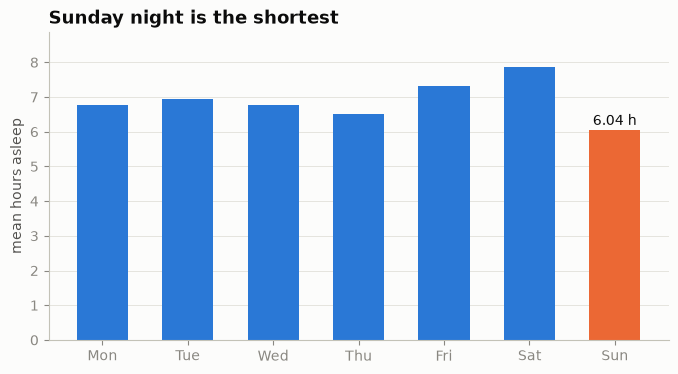

In [2]:
plots.weekday_bars(summary);

Sunday it is, and by a lot. Thursday is the second-worst, which I didn't expect.
Friday and Saturday look great but that's the lie-in — the next cell checks whether the
gap between weekday and weekend is just luck.

In [3]:
import numpy as np

worst = worst_weekday(nights)
gap = summary["mean_hours"].drop(worst).mean() - summary.loc[worst, "mean_hours"]

rng = np.random.default_rng(0)
hours = nights["hours"].to_numpy()
is_worst = (nights["weekday"] == worst).to_numpy()
null = np.array([
    hours[~p].mean() - hours[p].mean()
    for p in (rng.permutation(is_worst) for _ in range(5000))
])
print(f"{worst} is {gap * 60:.0f} min shorter than the other nights; permutation p = {(null >= gap).mean():.4f}")

Sunday is 60 min shorter than the other nights; permutation p = 0.0000
